# Análisis Exploratorio de Sismos
### Predicción de réplicas sísmicas · Ciencia de Datos

**La pregunta del proyecto.** ¿Cuántas réplicas produce un terremoto?

**Qué es una fila** Una secuencia sísmica: un terremoto principal con todas las réplicas que el declustering de Zaliapin & Ben-Zion le atribuyó. Son 1.978 secuencias, salidas de un catálogo de 2.321 eventos del USGS con magnitud ≥ 4,5, entre 2016-01-01 y 2026-01-01, dentro de la caja -55,-21,-74,-53 (Andes centrales: Chile, Argentina, Bolivia). En este análisis el sismo principal se considera el de mayor magnitud dentro de la secuencia.


# Dataset


In [1]:
import os

ARCHIVO  = "clusters_earthquake_starttime=2016-01-01_endtime=2026-01-01_minmagnitude=3.5_bbox=-55,-21,-74,-53_mainshock=largest_seed=1.csv"
ID_DRIVE = "1cEa_DIcsFCIeaKVkirhaGujOuc_KiHPG"

if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO

Downloading...
From: https://drive.google.com/uc?id=1cEa_DIcsFCIeaKVkirhaGujOuc_KiHPG
To: /content/clusters_earthquake_starttime=2016-01-01_endtime=2026-01-01_minmagnitude=3.5_bbox=-55,-21,-74,-53_mainshock=largest_seed=1.csv
100% 266k/266k [00:00<00:00, 12.0MB/s]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(ARCHIVO, low_memory=False)

# Plantillas

In [3]:
# Comparación de dos grupos: la separación estandarizada
def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

In [4]:
# Comparación de muchos grupos: η²
def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria, observed=True)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()

In [5]:
# Asociación entre dos numéricas: Pearson, Spearman y la brecha
def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

# Semáforo
# El semáforo
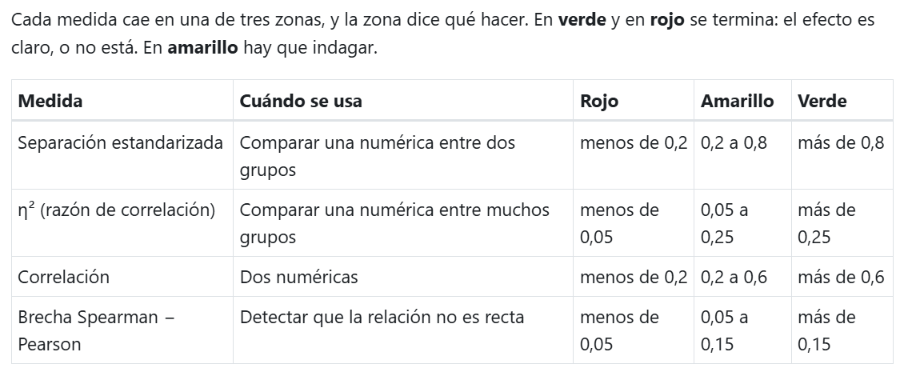


In [6]:
CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25),
          "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}


def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"

# Qué cambió desde la Entrega 1
El pipeline ahora le agrega a cada secuencia la profundidad (`mainshock_depth`) y el lugar (`mainshock_place`) del sismo principal, pasó los nombres de las columnas a inglés y dejó de publicar `raiz_id`: el dataset pasó de 14 a 15 columnas, con las mismas 1.978 filas. La pregunta del proyecto no cambió: **¿cuántas réplicas va a tener un sismo principal dado?** (`n_aftershocks`, que en la Entrega 1 se llamaba `n_replicas`).

| Entrega 1 | Entrega 2 |
|---|---|
| `n_eventos`, `n_replicas`, `n_premonitores` | `n_events`, `n_aftershocks`, `n_foreshocks` |
| `duracion_dias`, `extension_km`, `generacion_max` | `duration_days`, `extent_km`, `max_generation` |
| `raiz_es_mainshock` | `root_is_mainshock` |
| `raiz_id` | ya no se publica |
| — | **nuevas:** `mainshock_depth`, `mainshock_place` |

## El pendiente de la Entrega 1: los clusters geográficamente imposibles

En la guía de defensa marcamos 2 clusters de más de 1.500 km (el mayor, 3.610 km) y dijimos que se arreglaba cortando por profundidad en esta entrega. Lo volvemos a medir sobre el dataset actual:

In [7]:
gigantes = df[df["extent_km"] > 1500]

pd.Series({"clusters de más de 1.500 km": len(gigantes),
           "réplicas en esos clusters": int(gigantes["n_aftershocks"].sum()),
           "réplicas totales del dataset": int(df["n_aftershocks"].sum()),
           "% de las réplicas": round(gigantes["n_aftershocks"].sum() / df["n_aftershocks"].sum() * 100, 1)})

,0
clusters de más de 1.500 km,2.0
réplicas en esos clusters,6.0
réplicas totales del dataset,279.0
% de las réplicas,2.2


In [8]:
gigantes[["cluster_id", "mainshock_time", "mainshock_mag", "mainshock_depth",
          "mainshock_place", "n_aftershocks", "extent_km"]]

,cluster_id,mainshock_time,mainshock_mag,mainshock_depth,mainshock_place,n_aftershocks,extent_km
13,us6000a4yi,2020-06-03T07:35:36+0000,6.8,112.0,"48 km SW of San Pedro de Atacama, Chile",4,3610.028633
24,us10007mn3,2016-12-25T14:22:27+0000,7.6,38.0,"41 km SW of Quellón, Chile",2,2422.337960


**Qué encontramos:** siguen estando los mismos 2 clusters: `us6000a4yi` (M6,8 a 112 km de profundidad, 3.610 km de extensión) y `us10007mn3` (M7,6 a 38 km, 2.422 km). El corte por profundidad **no se aplicó** en el pipeline para esta entrega.

**Por qué no bloquea el EDA:** entre los dos suman 6 de las 279 réplicas del dataset (2,2 %), y la columna que los delata (`extent_km`) no entra al modelo porque es fuga (ver tabla de columnas candidatas). El único efecto es que esos 2 conteos de `n_aftershocks` pueden estar inflados por "réplicas" lejanas que en realidad no lo son.

**Decisión:** las 2 filas quedan en el dataset y quedan identificadas. Antes de la Entrega 3 hay que resolverlo en el pipeline, con una de dos opciones: el corte por profundidad que propusimos (`mindepth` / `maxdepth` en la consulta al FDSN) o un tope de distancia entre padre e hijo en `nearest_neighbor`. La Hipótesis 3 aporta un dato para elegir: la profundidad casi no separa la cantidad de réplicas, así que el corte se justifica por el método (poblaciones con estadística distinta), no por el objetivo.

# Inspección Inicial del dataset

In [9]:
df.shape

(1978, 15)

1.978 filas y 15 columnas. Una fila es una secuencia sísmica

## Tipos de dato

In [10]:
df.dtypes.value_counts()

,count
float64,6
object,4
int64,4
bool,1


In [11]:
df.dtypes

,0
cluster_id,object
mainshock_id,object
mainshock_place,object
mainshock_mag,float64
mainshock_time,object
mainshock_lat,float64
mainshock_lon,float64
mainshock_depth,float64
n_events,int64
n_aftershocks,int64


## Columnas y su media de nulos

In [12]:
df.isna().mean().sort_values(ascending=False)

,0
cluster_id,0.0
mainshock_id,0.0
mainshock_place,0.0
mainshock_mag,0.0
mainshock_time,0.0
mainshock_lat,0.0
mainshock_lon,0.0
mainshock_depth,0.0
n_events,0.0
n_aftershocks,0.0


Cero nulos en las 15 columnas.Cada fila se arma agregando eventos que ya existen, así que todos los campos salen calculados y ninguno puede faltar.

In [13]:
df.columns[df.nunique() <= 1]

Index([], dtype='object')

Ninguna constante: las 15 columnas varían. Los parámetros de la consulta que sí son constantes
(ventana temporal, caja, `mainshock=largest`, `seed=1`) quedaron en el **nombre del archivo** y no
como columnas, que es donde corresponde.

In [14]:
df["cluster_id"].duplicated().sum()

np.int64(0)

In [15]:
df["mainshock_id"].duplicated().sum()

np.int64(0)

La clave es `cluster_id` y da **cero duplicados**. `mainshock_id` también: ninguna secuencia comparte terremoto principal con otra, que es la condición que hace que una fila sea una unidad de predicción válida.

## La variable objetivo

`n_aftershocks`: cuántas réplicas dejó el terremoto principal de esa secuencia.

In [16]:
df["n_aftershocks"].value_counts(normalize=True)

,proportion
n_aftershocks,
0,0.933771
1,0.049039
2,0.008595
7,0.001517
4,0.001517
3,0.001517
6,0.001011
9,0.001011
12,0.000506


In [17]:
pd.Series({"secuencias":          len(df),
           "réplicas totales":    int(df["n_aftershocks"].sum()),
           "media":               df["n_aftershocks"].mean(),
           "varianza":            df["n_aftershocks"].var(),
           "varianza / media":    df["n_aftershocks"].var() / df["n_aftershocks"].mean(),
           "máximo":              int(df["n_aftershocks"].max())}).round(3)

,0
secuencias,1978.000
réplicas totales,279.000
media,0.141
varianza,1.266
varianza / media,8.978
máximo,32.000


Se puede observar que el 93,4 % de los mainshocks tiene cero réplicas. No es un desbalance de clases —el objetivo es un conteo, no una clase— pero tiene la misma consecuencia: cualquier modelo que conteste siempre "cero" acierta 1.847 de 1.978 veces.

La varianza sobre media = 9,0. Esto se conoce como sobredispersión.Un conteo de Poisson tiene varianza igual a la media. En este caso los datos tienen mucha más variabilidad de la que esperaría un modelo de Poisson simple.

In [18]:
#¿Cuántas réplicas acumulan los mainshocks cuya magnitud es mayor a 6.5?
grandes = df[df["mainshock_mag"] > 6.5]
grandes["n_aftershocks"].sum()

np.int64(103)

In [19]:
#¿Cuántos eventos corresponden?
len(grandes)

12

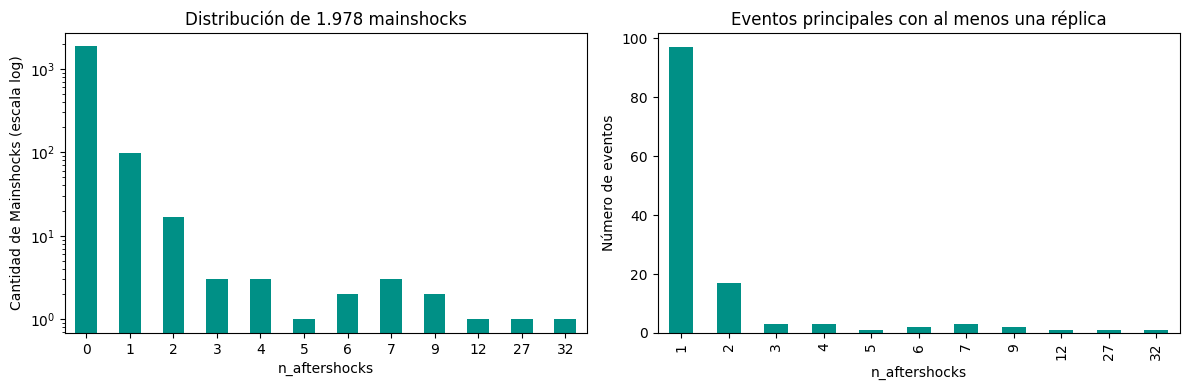

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["n_aftershocks"].value_counts().sort_index().plot.bar(ax=axes[0], color="#009086", rot=0,
        title="Distribución de 1.978 mainshocks", logy=True)
axes[0].set_xlabel("n_aftershocks"); axes[0].set_ylabel("Cantidad de Mainshocks (escala log)")

df.loc[df["n_aftershocks"] > 0, "n_aftershocks"].value_counts().sort_index().plot.bar(
    ax=axes[1],
    color="#009086",
    title="Eventos principales con al menos una réplica"
)
axes[1].set_xlabel("n_aftershocks")
axes[1].set_ylabel("Número de eventos")

plt.tight_layout(); plt.show()

In [21]:
df.loc[df["n_aftershocks"] > 0, "n_aftershocks"].value_counts().sort_index()

,count
n_aftershocks,
1,97
2,17
3,3
4,3
5,1
6,2
7,3
9,2
12,1


El eje logarítmico del primer panel permite ver las barras, que con una escala normal quedarían prácticamente ocultas. La distribución está muy concentrada en cero: hay 1.847 casos sin réplicas, 97 con una, 17 con dos y, a partir de ahí, casos aislados que llegan hasta 32.

El segundo panel muestra la distribución solo entre los casos que tienen al menos una réplica.

En resumen, la cantidad de réplicas tiene una distribución muy desigual: la mayoría de los casos no tiene ninguna, algunos tienen una o unas pocas, y unos pocos casos presentan muchas.

In [22]:
df.select_dtypes("number").skew().sort_values(ascending=False)

,0
duration_days,26.016493
extent_km,24.930532
n_foreshocks,22.438187
n_events,22.354058
n_aftershocks,20.132167
max_generation,8.286410
mainshock_mag,2.370335
mainshock_depth,2.081619
mainshock_lon,0.690653
mainshock_lat,-1.277751


- `duration_days`, `extent_km`, `n_foreshocks`, `n_events` y `n_aftershocks` tienen un skew muy alto, porque la mayoría de las secuencias tienen valores pequeños y unas pocas tienen valores extremadamente grandes.

- El 92 % de las secuencias tiene un solo evento. Por eso `duration_days` y `extent_km` valen 0 en casi todas las filas: una secuencia de un solo sismo no puede durar ni extenderse. Ese 0 es estructural, viene de cómo se construye la columna. En cambio, el 0 de `n_aftershocks` es un cero real: el terremoto ocurrió y no dejó réplicas.

- `mainshock_mag` tiene un skew de 2,37, lo que significa que hay muchos terremotos pequeños y pocos terremotos grandes. La ley de Gutenberg-Richter dice que muchos sismos chicos y pocos grandes, lo cual es coherente con la forma real del fenómeno.

- `mainshock_depth` tiene un skew de 2,08, porque combina terremotos superficiales con terremotos profundos.

- `mainshock_lon` y `mainshock_lat` son las variables más equilibradas, porque sus valores de skew son los más cercanos a 0.

- `n_aftershocks` tiene un skew de 20,13, por lo que tiene una cola muy larga: muchas secuencias tienen pocas o ninguna réplica y unas pocas tienen muchísimas.

# Análisis univariado


In [23]:
features = ["mainshock_mag", "mainshock_depth", "mainshock_lat", "mainshock_lon","n_aftershocks"]
df[features].describe().round(2)

,mainshock_mag,mainshock_depth,mainshock_lat,mainshock_lon,n_aftershocks
count,1978.00,1978.00,1978.00,1978.00,1978.00
mean,4.79,112.56,-27.58,-69.01,0.14
std,0.40,91.54,5.40,2.47,1.13
min,4.50,4.30,-54.57,-74.00,0.00
25%,4.50,38.51,-31.30,-71.28,0.00
50%,4.60,107.99,-27.17,-68.76,0.00
75%,4.90,165.16,-23.10,-67.14,0.00
max,7.60,597.13,-21.01,-55.26,32.00


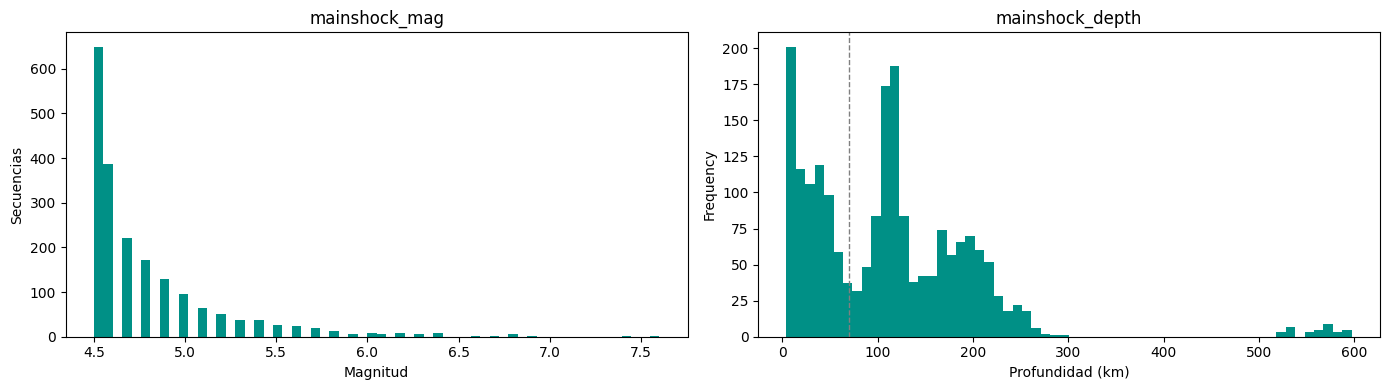

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df["mainshock_mag"].plot.hist(bins=60, ax=axes[0], color="#009086",
                              title="mainshock_mag")
axes[0].set_xlabel("Magnitud"); axes[0].set_ylabel("Secuencias")

df["mainshock_depth"].plot.hist(bins=60, ax=axes[1], color="#009086", title="mainshock_depth")
axes[1].axvline(70, color="grey", ls="--", lw=1)
axes[1].set_xlabel("Profundidad (km)")

plt.tight_layout(); plt.show()

`mainshock_mag`: El catálogo comienza en M = 4,5, aunque la consulta al USGS pedía minmagnitude=3.5. Hay aproximadamente 650 eventos que caen exactamente en 4,5. Esto es debido a que 4,5 es el umbral de completitud usado en el análisis: por debajo de ese valor la red no detecta los eventos de forma uniforme. Por eso, `n_aftershocks` representa las réplicas detectadas con M ≥ 4,5, no todas las réplicas reales lo cual es correcto.

`mainshock_depth`: presenta una distribución con diferentes zonas de profundidad. Se observa una gran concentración de terremotos entre 0 y 300 km y un grupo separado de terremotos muy profundos, alrededor de 515–600 km.

In [25]:
df["mainshock_place"].str.split(", ").str[-1].value_counts(normalize=True)

,proportion
mainshock_place,
Chile,0.563701
Argentina,0.389788
Bolivia,0.032356
Falkland Islands region,0.007078
Chile-Argentina border region,0.005561
Chile-Bolivia border region,0.001517


`place`:  es un texto libre del USGS que suele seguir el formato «distancia + referencia + país». Aunque permite identificar el país de cada evento (Chile 56 % y Argentina 39 %), esta columna se descarta y no se utiliza en el modelo. Para representar la ubicación geográfica se mantienen latitude y longitude, que son variables numéricas y no dependen de la descripción textual del USGS.

# Análisis bivariado


In [26]:
df[features].corr().round(2).style.background_gradient(cmap="RdBu", vmin=-1, vmax=1)

,mainshock_mag,mainshock_depth,mainshock_lat,mainshock_lon,n_aftershocks
mainshock_mag,1.000000,-0.030000,-0.100000,-0.090000,0.390000
mainshock_depth,-0.030000,1.000000,0.440000,0.660000,-0.050000
mainshock_lat,-0.100000,0.440000,1.000000,0.370000,-0.030000
mainshock_lon,-0.090000,0.660000,0.370000,1.000000,-0.060000
n_aftershocks,0.390000,-0.050000,-0.030000,-0.060000,1.000000


- `mainshock_depth` y `mainshock_lon` tienen una correlación de 0,66, lo que indica una relación positiva relativamente fuerte entre la profundidad y la longitud.

- `mainshock_depth` y `mainshock_lat` tienen una correlación de 0,44, lo que indica una relación positiva moderada entre la profundidad y la latitud.

- `mainshock_lat` y `mainshock_lon` tienen una correlación de 0,37, por lo que existe una relación positiva, aunque más débil, entre ambas coordenadas geográficas.

- `mainshock_mag` presenta correlaciones muy bajas con las demás variables.Esto significa que aporta información diferente y puede ser una feature útil para el modelo.
-  `n_aftershocks` muestra la relación de cada variable con el objetivo. `mainshock_mag` tiene 0,39, la más alta de las cuatro. Las otras tres quedan cerca de cero: −0,05 la profundidad, −0,03 la latitud y −0,06 la longitud. De las variables disponibles, la magnitud es la única que se mueve junto con la cantidad de réplicas.

En conclusión: las variables muy correlacionadas pueden aportar información repetida, mientras que `mag` aporta información nueva.

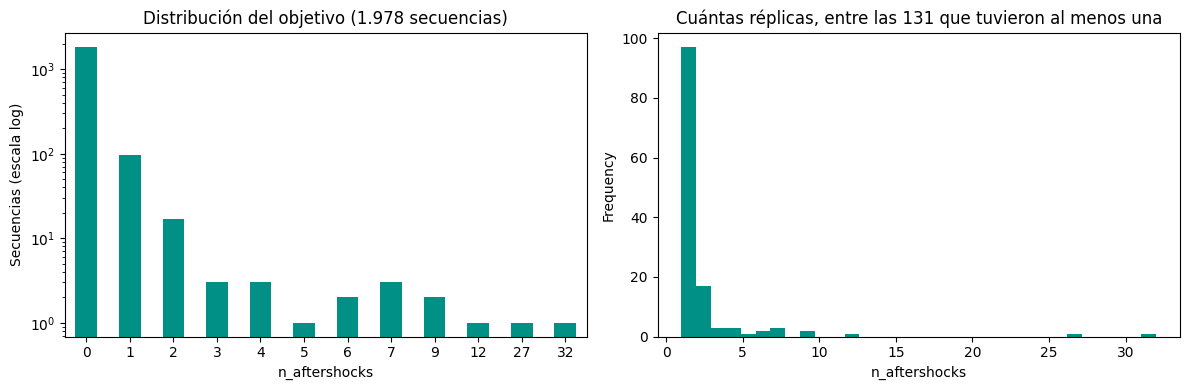

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["n_aftershocks"].value_counts().sort_index().plot.bar(
    ax=axes[0], color="#009086", rot=0, logy=True,
    title="Distribución del objetivo (1.978 secuencias)")
axes[0].set_xlabel("n_aftershocks"); axes[0].set_ylabel("Secuencias (escala log)")

df.loc[df["n_aftershocks"] > 0, "n_aftershocks"].plot.hist(
    bins=32, ax=axes[1], color="#009086",
    title="Cuántas réplicas, entre las 131 que tuvieron al menos una")
axes[1].set_xlabel("n_aftershocks")

plt.tight_layout(); plt.show()

# Análisis temporal

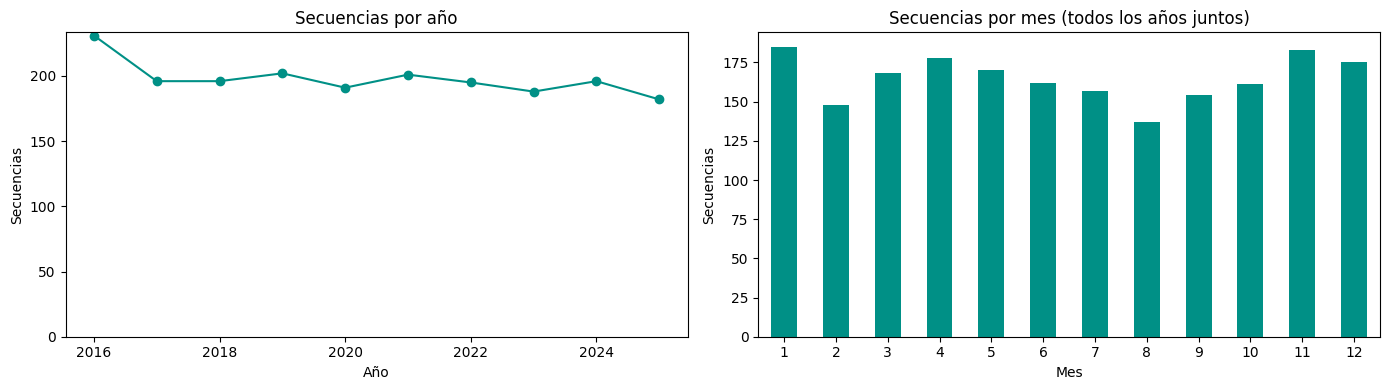

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Fechas de las secuencias
fechas = pd.to_datetime(df["mainshock_time"], utc=True)

# Secuencias por año
secuencias_por_año = fechas.dt.year.value_counts().sort_index()

secuencias_por_año.plot(
    kind="line",
    marker="o",
    ax=axes[0],
    color="#009086",
    title="Secuencias por año"
)

axes[0].set_xlabel("Año")
axes[0].set_ylabel("Secuencias")
axes[0].set_ylim(0, None)

# Secuencias por mes
secuencias_por_mes = fechas.dt.month.value_counts().sort_index()

secuencias_por_mes.plot(
    kind="bar",
    ax=axes[1],
    color="#009086",
    rot=0,
    title="Secuencias por mes (todos los años juntos)"
)

axes[1].set_xlabel("Mes")
axes[1].set_ylabel("Secuencias")
axes[1].set_ylim(0, None)

plt.tight_layout()
plt.show()


Se observa entre aproximadamente 180 y 230 secuencias por año, sin tendencia.

In [29]:
resultado = pd.Series({
    "eta2 de replicas por año": eta2(df["n_aftershocks"], fechas.dt.year),
    "eta2 de replicas por mes": eta2(df["n_aftershocks"], fechas.dt.month)
}).round(4)

pd.DataFrame({
    "eta2": resultado,
    "semaforo": [
        semaforo(resultado["eta2 de replicas por año"], "eta2"),
        semaforo(resultado["eta2 de replicas por mes"], "eta2")
    ]
})

,eta2,semaforo
eta2 de replicas por año,0.0045,rojo
eta2 de replicas por mes,0.0062,rojo


Como se puede observar, ambos valores se encuentran en la zona roja, lo que indica que ni el año ni el mes presentan una asociación relevante con la variación en la cantidad de réplicas. En consecuencia, no se observa una estacionalidad temporal significativa en la sismicidad analizada.

# Columnas Agregadas

Hasta acá analizamos características del sismo principal (magnitud, profundidad, coordenadas). Sin embargo, el pipeline también genera cinco columnas calculadas recorriendo la secuencia completa una vez que terminó: `n_events`, `n_foreshocks`, `duration_days`, `extent_km` y `max_generation`.

Antes de considerarlas como features, vamos a medir su asociación con nuestro objetivo (`n_aftershocks`). Como son variables numéricas, usamos la función asociación que calcula Pearson, Spearman y la brecha entre ambos, sumando las features originales como línea de base.

In [30]:
columnas_agregadas = ["n_events", "max_generation", "n_foreshocks", "duration_days", "extent_km"]
columnas_base = ["mainshock_mag", "mainshock_depth"]

# Calculamos la asociación de cada columna contra la variable objetivo
resultados = pd.DataFrame({
    col: asociacion(df[col], df["n_aftershocks"])
    for col in columnas_agregadas + columnas_base
}).T

# Ordenamos por la correlación de Pearson
resultados.sort_values(by="pearson", ascending=False)

,pearson,spearman,brecha
n_events,0.978,0.904,-0.074
max_generation,0.692,0.902,0.210
n_foreshocks,0.535,0.161,-0.375
mainshock_mag,0.393,0.280,-0.113
duration_days,0.371,0.904,0.532
extent_km,0.176,0.902,0.726
mainshock_depth,-0.050,-0.059,-0.010


- `n_events` presenta una correlación muy alta con n_aftershocks (Pearson = 0.978), lo cual es una correlación casi perfecta. Esto es una señal para revisar esta variable con cuidado, porque una relación tan alta puede significar que contiene información muy cercana a la propia variable que queremos predecir.

- `max_generation`, `duration_days` y `extent_km` describen una secuencia que ya terminó: cuántos niveles de réplicas hubo, cuánto duró, cuánto se extendió. Nada de eso existe en el instante en que hay que predecir, por lo tanto no nos sirven esas columnas.

In [31]:
df.groupby(df["n_foreshocks"] > 0).agg(clusters=("n_aftershocks", "size"),
                                       replicas_promedio=("n_aftershocks", "mean")).round(3)

,clusters,replicas_promedio
n_foreshocks,,
False,1936,0.114
True,42,1.405


Las secuencias con al menos un premonitor promedian 1,40 réplicas contra 0,114 las que no tienen ninguno.

Sin embargo, hay que tener cuidado con esta variable porque premonitor se determina mirando lo que ocurrió después. Es decir, un evento se identifica como premonitor porque posteriormente ocurrió un evento de mayor magnitud.

Por lo tanto, `n_foreshocks` no debería utilizarse directamente como predictor, ya que en el momento de hacer la predicción todavía no sabemos si ese evento será considerado un premonitor.

In [32]:
df.groupby("root_is_mainshock").agg(clusters=("n_aftershocks", "size"),
                                    replicas_promedio=("n_aftershocks", "mean")).round(3)

,clusters,replicas_promedio
root_is_mainshock,,
False,42,1.405
True,1936,0.114


La variable `root_is_mainshock` muestra prácticamente el mismo patrón: 42 secuencias tienen un promedio de 1,405 réplicas, frente a 0,114.
Esto también es información retrospectiva, porque para saber que una secuencia cambió de evento principal hay que esperar a que ocurra un evento posterior de mayor magnitud.

Por eso, tanto `n_foreshocks` como `root_is_mainshock` estas variables muestran que existe una señal interesante, pero no son adecuadas para predecir en tiempo real, porque utilizan información que solo se conoce después de que la secuencia terminó.

# Hipótesis


## Hipótesis 1 - El número de réplicas crece con la magnitud del sismo principal
- **Afirmación**: El número de réplicas crece a medida que crece la maginitud del terremoto principal.

- **Qué espero ver**: Una correlación lineal positiva y fuerte entre la magnitud del sismo (mainshock_mag) y la cantidad de réplicas (n_aftershocks).

- **Cómo la mido**: Mediante la correlación de pearson, ya que es la métrica directa para evaluar si dos variables numéricas continuas suben juntas de forma proporcional.







In [33]:
h1 = asociacion(df["mainshock_mag"], df["n_aftershocks"])
h1

,0
pearson,0.393
spearman,0.280
brecha,-0.113


In [34]:
pd.Series({"correlación": semaforo(h1["pearson"], "correlacion"),
           "brecha":      semaforo(h1["brecha"],  "brecha")})

,0
correlación,amarillo
brecha,amarillo


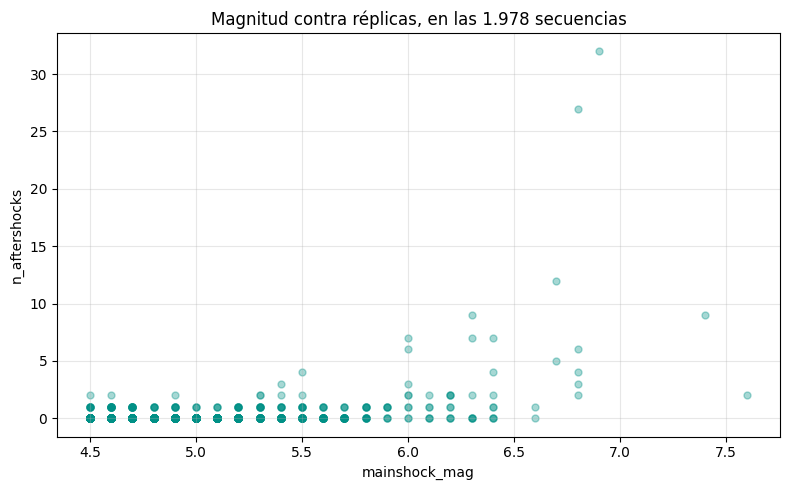

In [56]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df["mainshock_mag"], df["n_aftershocks"], s=25, alpha=.35, color="#009086")

ax.set_title("Magnitud contra réplicas, en las 1.978 secuencias")
ax.set_xlabel("mainshock_mag")
ax.set_ylabel("n_aftershocks")
ax.grid(alpha=.3)

plt.tight_layout()
plt.show()

**Qué encontré:** Semáforo amarillo. El Pearson da bajo porque busca principalmente relaciones lineales, y en este caso como analizamos anteriormente los datos tienen muchos ceros y algunos valores muy altos, por lo que la distribución es bastante desigual.

Además, la relación entre la magnitud y la cantidad de réplicas, según la Ley de Utsu, no sigue una relación lineal sino exponencial.

**Movimiento 1:** Agrupar por rangos de magnitud

Agrupamos los eventos por rangos de magnitud y analizamos cómo varía el promedio de réplicas entre esos grupos, utilizando η², que permite detectar relaciones no lineales, y una escala logarítmica para representar mejor los valores extremos.

In [35]:
df["tramo_mag"] = pd.cut(df["mainshock_mag"], [4.4, 5.0, 5.5, 6.0, 6.5, 8.0])

e1 = eta2(df["n_aftershocks"], df["tramo_mag"])
pd.Series({"eta2": round(e1, 3), "zona": semaforo(e1, "eta2")})

,0
eta2,0.377
zona,verde


In [36]:
tramos = df.groupby("tramo_mag", observed=True).agg(
    clusters=("n_aftershocks", "size"),
    replicas=("n_aftershocks", "sum"),
    promedio=("n_aftershocks", "mean"),
    maximo=("n_aftershocks", "max")).round(3)
tramos

,clusters,replicas,promedio,maximo
tramo_mag,,,,
"(4.4, 5.0]",1651,50,0.030,2
"(5.0, 5.5]",215,43,0.200,4
"(5.5, 6.0]",71,38,0.535,7
"(6.0, 6.5]",29,45,1.552,9
"(6.5, 8.0]",12,103,8.583,32


In [37]:
# ¿Es multiplicativa? La pendiente del promedio en escala logarítmica
puntos = np.array([4.75, 5.25, 5.75, 6.25, 7.0])
pendiente, _ = np.polyfit(puntos, np.log10(tramos["promedio"]), 1)

pd.Series({"pendiente (log10 réplicas por punto de magnitud)": round(pendiente, 2),
           "factor por cada punto de magnitud":                round(10 ** pendiente, 1)})

,0
pendiente (log10 réplicas por punto de magnitud),1.05
factor por cada punto de magnitud,11.20


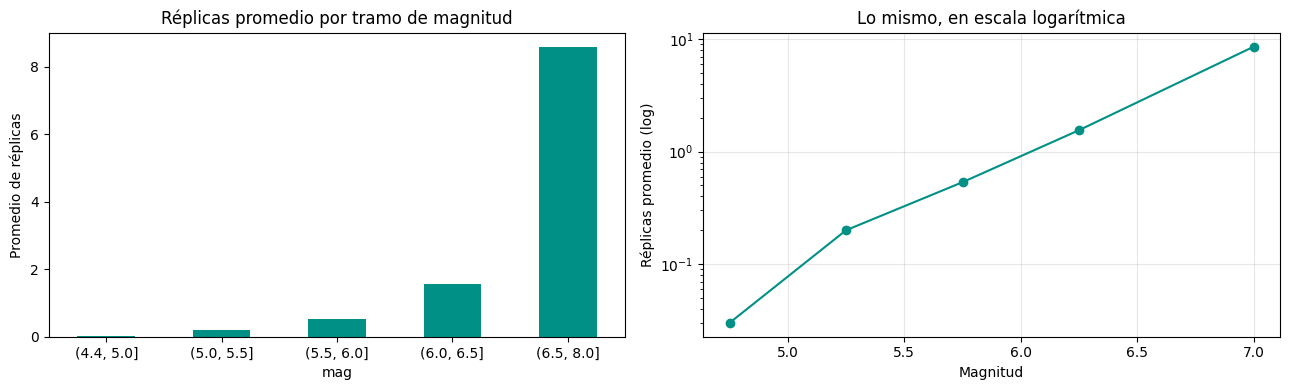

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

tramos["promedio"].plot.bar(ax=axes[0], color="#009086", rot=0,
                            title="Réplicas promedio por tramo de magnitud")
axes[0].set_xlabel("mag"); axes[0].set_ylabel("Promedio de réplicas")

axes[1].plot(puntos, tramos["promedio"], "o-", color="#009086")
axes[1].set_yscale("log"); axes[1].set_title("Lo mismo, en escala logarítmica")
axes[1].set_xlabel("Magnitud"); axes[1].set_ylabel("Réplicas promedio (log)")
axes[1].grid(alpha=.3)

plt.tight_layout(); plt.show()

**Qué encontré:** η² = 0,377 significa que los rangos de magnitud tienen una relación importante con la cantidad de réplicas, por lo tanto **la hipótesis queda confirmada**.

En la gráfica cuando llevamos estos valores a una escala logarítmica, los puntos quedan aproximadamente alineados. La pendiente de 1,05 indica que la cantidad de réplicas aumenta muy rápidamente a medida que aumenta la magnitud.

**Qué hago con eso:**
* `mainshock_mag` debe formar parte del modelo, porque es una de las variables que muestra una relación clara con la cantidad de réplicas.

* No conviene asumir una relación lineal simple. Los datos muestran un crecimiento mucho más parecido a una relación multiplicativa. Por eso tiene sentido utilizar modelos de conteo, como Poisson o binomial negativa, o modelos que puedan capturar relaciones no lineales.

## Hipótesis 2 - `n_events` y `n_aftershocks` miden lo mismo

- **Afirmación**: `n_events` no debería usarse como feature porque está directamente relacionada con la cantidad de réplicas que queremos predecir. Incluirla podría hacer que el modelo reciba información que ya forma parte de la respuesta.

- **Qué espero ver**: Una correlación muy alta entre n_events y n_aftershocks

- **Cómo la mido**: Usamos la correlación para detectar que ambas variables están prácticamente contando lo mismo.


In [39]:
h2 = asociacion(df["n_events"], df["n_aftershocks"])
pd.Series({"pearson": h2["pearson"], "spearman": h2["spearman"],
           "zona": semaforo(h2["pearson"], "correlacion")})

,0
pearson,0.978
spearman,0.904
zona,verde


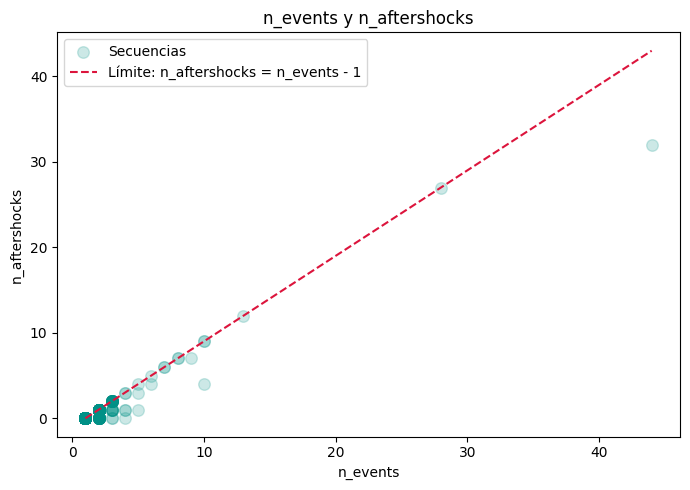

In [40]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(df["n_events"], df["n_aftershocks"], s=70, alpha=0.20, color="#009086", label="Secuencias")

x_vals = np.array([1, df["n_events"].max()])
ax.plot(x_vals, x_vals - 1, color="crimson", linestyle="--", label="Límite: n_aftershocks = n_events - 1")

ax.set_xlabel("n_events")
ax.set_ylabel("n_aftershocks")
ax.set_title("n_events y n_aftershocks")
ax.legend()

plt.tight_layout()
plt.show()

In [41]:
pd.Series({"filas donde n_events = 1 + n_aftershocks + n_foreshocks":
           (df["n_events"] == 1 + df["n_aftershocks"] + df["n_foreshocks"]).mean(),
           "secuencias con al menos un precursor": int((df["n_foreshocks"] > 0).sum())})

,0
filas donde n_events = 1 + n_aftershocks + n_foreshocks,1.0
secuencias con al menos un precursor,42.0


**Qué encontré:** Se obtuvo un coeficiente de correlación de Pearson de 0,978, lo cual es coherente con la forma en que se construye `n_events`en el pipeline, ya que `n_events = 1 + n_aftershocks + n_foreshocks`. La correlación no llega a 1 porque existen 42 secuencias con premonitores, que hacen que `n_events` sea mayor que 1 + n_aftershocks.

Sin embargo, este análisis también muestra por qué estas variables no deben utilizarse directamente para predecir `n_aftershocks`: los premonitores ocurren antes del evento principal y su cantidad no se conoce al momento de realizar la predicción. Además, dado que `n_events` se construye como `1 + n_aftershocks + n_foreshocks`, proporcionar al modelo estas variables le permitiría reconstruir prácticamente el valor objetivo. En particular, si no existen premonitores, se cumple `n_events = 1 + n_aftershocks`, por lo que el modelo podría obtener la respuesta directamente a partir de las variables de entrada, en lugar de aprender a predecirla, lo cual constituye una fuga de información.

**Qué hago con eso:** `n_events` es el caso más claro de fuga de información de la tabla. Por este motivo, `n_events` debe excluirse de las variables predictoras.

## Hipótesis 3 - Los sismos superficiales dejan más réplicas que los profundos
- **Afirmación**: los sismos principales superficiales (menos de 70 km) dejan más réplicas que los intermedios y profundos. En la guía de defensa de la Entrega 1 ya dijimos que en esta región la sismicidad superficial andina y la del slab profundo son poblaciones distintas, y en sismología los sismos profundos son conocidos por dejar pocas réplicas.

- **Qué espero ver**: un promedio de réplicas claramente mayor en la franja superficial que en el resto.

- **Cómo la mido**: es una comparación de dos grupos, así que uso la **separación estandarizada** entre someras (< 70 km) y el resto (≥ 70 km).

In [42]:
someros = df.loc[df["mainshock_depth"] < 70, "n_aftershocks"]
profundos = df.loc[df["mainshock_depth"] >= 70, "n_aftershocks"]

h3_sep = separacion(someros, profundos)

s_prof = separacion(someros, profundos)
pd.Series({"secuencias someras":   len(someros),
           "secuencias profundas": len(profundos),
           "promedio someros":     round(someros.mean(), 3),
           "promedio profundos":   round(profundos.mean(), 3),
           "separacion":           round(s_prof, 3),
           "zona":                 semaforo(s_prof, "separacion")})

,0
secuencias someras,722
secuencias profundas,1256
promedio someros,0.251
promedio profundos,0.078
separacion,0.134
zona,rojo


**Qué encontré:** Separación = **0,1, semáforo rojo**. Esto indica que, considerando todos los sismos juntos, la profundidad prácticamente no permite distinguir entre las secuencias con mayor o menor cantidad de réplicas.

**Movimiento 1:** Análisis por franjas con η²

Como el primer análisis no mostró una relación clara, quizás el problema estaba en la forma de agrupar las profundidades.

Probamos con η² sobre tres franjas (0–70, 70–300 y más de 300 km). El corte de 70 km es el límite estándar entre sismos superficiales e intermedios, el mismo que marcamos en el histograma de profundidad y vemos si mejoramos el resultado.

In [43]:
df["franja_prof"] = pd.cut(df["mainshock_depth"], [-1, 70, 300, 800],
                          labels=["superficial (<70 km)", "intermedio (70-300 km)", "profundo (>300 km)"])
h3_eta = eta2(df["n_aftershocks"], df["franja_prof"])
pd.DataFrame({
        "valor": [round(h3_eta, 4)],
        "zona": [semaforo(h3_eta, "eta2")]
    }, index=["η² (3 franjas)"])


,valor,zona
η² (3 franjas),0.0055,rojo


In [44]:
franjas = df.groupby("franja_prof", observed=True).agg(
    clusters=("n_aftershocks", "size"),
    replicas=("n_aftershocks", "sum"),
    promedio=("n_aftershocks", "mean"),
    con_al_menos_una=("n_aftershocks", lambda x: (x > 0).mean()),
    mag_media=("mainshock_mag", "mean")).round(3)
franjas

,clusters,replicas,promedio,con_al_menos_una,mag_media
franja_prof,,,,,
superficial (<70 km),722,181,0.251,0.084,4.844
intermedio (70-300 km),1221,93,0.076,0.054,4.740
profundo (>300 km),35,5,0.143,0.114,5.149


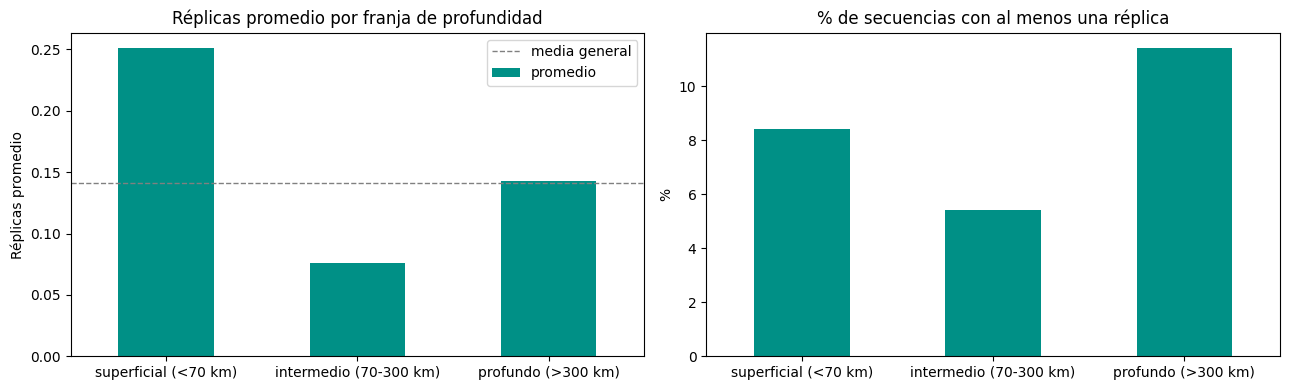

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

franjas["promedio"].plot.bar(ax=axes[0], color="#009086", rot=0,
                             title="Réplicas promedio por franja de profundidad")
axes[0].axhline(df["n_aftershocks"].mean(), color="grey", ls="--", lw=1, label="media general")
axes[0].set_xlabel(""); axes[0].set_ylabel("Réplicas promedio"); axes[0].legend()

(franjas["con_al_menos_una"] * 100).plot.bar(ax=axes[1], color="#009086", rot=0,
                                           title="% de secuencias con al menos una réplica")
axes[1].set_xlabel(""); axes[1].set_ylabel("%")

plt.tight_layout(); plt.show()

**Qué encontré:** El resultado fue 0.0055, nuevamente Rojo. Esto muestra que cambiar la forma de agrupar las profundidades no alcanza para encontrar una relación. Observando el csv, la mayoría de las secuencias en todas las franjas no tiene réplicas, por lo que cambiar la forma de agrupar no hace aparecer el efecto.

**Movimiento 2:** Controlar por magnitud

Después de estos dos resultados, se observa que quizás la profundidad no era suficiente por sí sola y que su efecto podía depender de la magnitud del terremoto. Tiene sentido probarlo porque los sismos más grandes tienen una mayor capacidad de generar réplicas.

Por eso, repetimos el análisis original, pero esta vez solamente con las secuencias cuya magnitud es mayor a 6.0.

In [46]:
mag_mayor_6 = df[df["mainshock_mag"] > 6.0]

s_prof_6 = separacion(
    mag_mayor_6.loc[mag_mayor_6["mainshock_depth"] < 70, "n_aftershocks"],
    mag_mayor_6.loc[mag_mayor_6["mainshock_depth"] >= 70, "n_aftershocks"]
)
pd.Series({
    "separacion (sólo magnitud > 6)": round(s_prof_6, 3),
    "zona": semaforo(s_prof_6, "separacion")
})

,0
separacion (sólo magnitud > 6),0.613
zona,amarillo


In [47]:
mag_mayor_6.groupby(mag_mayor_6["mainshock_depth"] < 70).agg(
    secuencias=("n_aftershocks", "size"),
    promedio=("n_aftershocks", "mean"),
    mediana=("n_aftershocks", "median"),
    maximo=("n_aftershocks", "max")).rename(index={True: "someros", False: "profundos"}).round(2)

,secuencias,promedio,mediana,maximo
mainshock_depth,,,,
profundos,22,1.73,1.0,9
someros,19,5.79,2.0,32


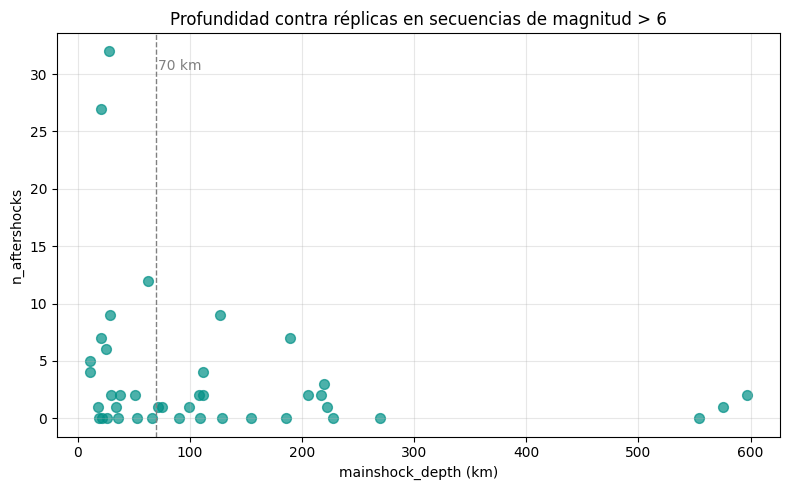

In [48]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(mag_mayor_6["mainshock_depth"], mag_mayor_6["n_aftershocks"], s=50, alpha=.7,
           color="#009086")
ax.axvline(70, color="grey", ls="--", lw=1)
ax.text(72, mag_mayor_6["n_aftershocks"].max() * .95, "70 km", color="grey")

ax.set_title("Profundidad contra réplicas en secuencias de magnitud > 6")
ax.set_xlabel("mainshock_depth (km)"); ax.set_ylabel("n_aftershocks")
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Qué encontré:** En este caso, la separación entre sismos someros y profundos aumentó bastante, pasando a 0.613, por lo que el resultado fue Amarillo. Además, los 19 terremotos someros tuvieron en promedio 5.79 réplicas, mientras que los 22 terremotos profundos tuvieron un promedio de 1.73 réplicas. A su vez, el gráfico muestra claramente que todas las secuencias con más de 10 réplicas están a la izquierda de la línea de 70 km. Esto nos muestra que, cuando tenemos en cuenta la magnitud, la profundidad empieza a mostrar una relación mucho más clara con la cantidad de réplicas.

**Qué hago con eso:** Con estos análisis agotamos los dos movimientos que teníamos disponibles para explorar la hipótesis. Los primeros resultados muestran que la profundidad, tomada por sí sola, no alcanza para separar las secuencias. Sin embargo, al controlar por magnitud aparece una diferencia mucho más marcada.

Por eso, decidimos mantener `mainshock_depth` en el modelo, pero no interpretarla como una variable que funciona de manera aislada. Su efecto parece estar relacionado con la magnitud del sismo.

## Hipótesis 4 - Con la magnitud alcanza para saber cuántas réplicas va a tener un terremoto

- **Afirmación**: entre los terremotos grandes, la magnitud determina la cantidad de réplicas donde si conozco la magnitud, sé cuántas réplicas va a haber.

- **Qué espero ver**: una correlación fuerte  entre `mainshock_mag` y `n_aftershocks` dentro de los terremotos grandes, y poca diferencia de réplicas entre terremotos de magnitud parecida.

- **Cómo la mido**: con la asociación (Pearson y Spearman) entre magnitud y réplicas, sólo en secuencias de magnitud mayor a 6. Ya vimos que las secuencias de magnitud menor a 6 producen pocas réplicas y la gran mayoría no producen ninguna réplica.

In [49]:
h4= asociacion(mag_mayor_6["mainshock_mag"], mag_mayor_6["n_aftershocks"])
pd.Series({"pearson":        h4["pearson"],
           "spearman":       h4["spearman"],
           "zona (pearson)": semaforo(h4["pearson"], "correlacion")})

,0
pearson,0.434
spearman,0.517
zona (pearson),amarillo


In [50]:
pd.Series({"secuencias con magnitud > 6": len(mag_mayor_6),
           "réplicas promedio":           mag_mayor_6["n_aftershocks"].mean(),
           "desvío estándar":             mag_mayor_6["n_aftershocks"].std(),
           "coeficiente de variación":    mag_mayor_6["n_aftershocks"].std() / mag_mayor_6["n_aftershocks"].mean(),
           "mínimo":                      mag_mayor_6["n_aftershocks"].min(),
           "máximo":                      mag_mayor_6["n_aftershocks"].max()}).round(2)

,0
secuencias con magnitud > 6,41.00
réplicas promedio,3.61
desvío estándar,6.64
coeficiente de variación,1.84
mínimo,0.00
máximo,32.00


In [51]:
# Los doce terremotos más grandes del catálogo
df.nlargest(12, "mainshock_mag")[["mainshock_time", "mainshock_mag", "mainshock_depth",
                                  "n_aftershocks", "mainshock_place"]]

,mainshock_time,mainshock_mag,mainshock_depth,n_aftershocks,mainshock_place
24,2016-12-25T14:22:27+0000,7.6,38.000,2,"41 km SW of Quellón, Chile"
4,2024-07-19T01:50:48+0000,7.4,127.291,9,"41 km ESE of San Pedro de Atacama, Chile"
0,2017-04-24T21:38:30+0000,6.9,28.000,32,"40 km W of Valparaíso, Chile"
1,2020-09-01T04:09:28+0000,6.8,21.000,27,"86 km NW of Vallenar, Chile"
9,2019-08-01T18:28:07+0000,6.8,25.000,6,"96 km SW of San Antonio, Chile"
13,2020-06-03T07:35:36+0000,6.8,112.000,4,"48 km SW of San Pedro de Atacama, Chile"
14,2022-05-10T23:06:32+0000,6.8,220.000,3,"86 km NNW of San Antonio de los Cobres, Argentina"
20,2023-01-20T22:09:39+0000,6.8,596.837,2,"29 km SW of Campo Gallo, Argentina"
2,2019-01-20T01:32:52+0000,6.7,63.000,12,"10 km SSW of Coquimbo, Chile"
10,2019-09-29T15:57:53+0000,6.7,11.000,5,"70 km WSW of Constitución, Chile"


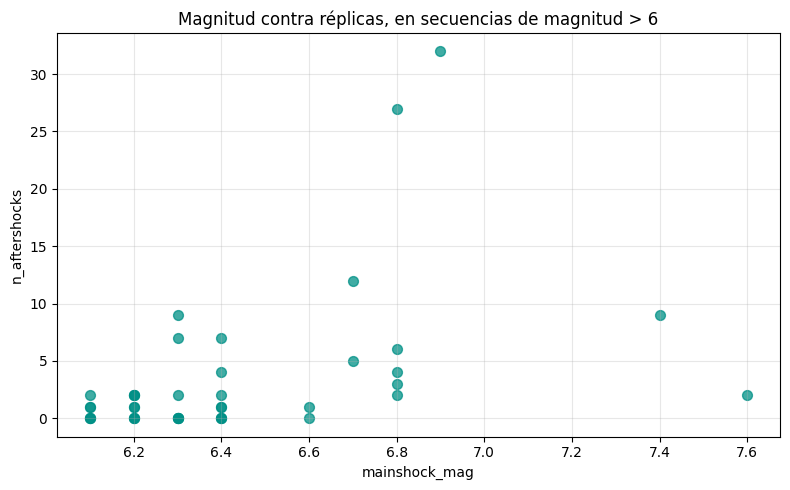

In [52]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(mag_mayor_6["mainshock_mag"], mag_mayor_6["n_aftershocks"], s=50, alpha=.75,
           color="#009086")

ax.set_title("Magnitud contra réplicas, en secuencias de magnitud > 6")
ax.set_xlabel("mainshock_mag");
ax.set_ylabel("n_aftershocks")
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Qué encontré:** El gráfico muestra que hay cierta relación entre la magnitud del terremoto y la cantidad de réplicas, pero no es una relación tan clara como esperábamos. El coeficiente de Pearson dio de 0,43, lo que indica una relación positiva moderada.

Además, cuando comparamos terremotos de magnitudes parecidas, la cantidad de réplicas cambia bastante. Por ejemplo, hay casos con 0 réplicas y otros con hasta 32, aunque la magnitud de los terremotos sea similar. Esto se refleja también en el coeficiente de variación, que es de 1,84.

Un ejemplo que llama bastante la atención es el terremoto de M7,6 ocurrido en Quellón (Chile), que tuvo solamente 2 réplicas. En cambio, un terremoto de M6,9 en Valparaíso tuvo 32 réplicas. Si la cantidad de réplicas dependiera principalmente de la magnitud, esperaríamos que el terremoto más grande tuviera muchas más réplicas, pero en los datos no ocurre eso.


Antes de dar la hipótesis por refutada hay que descartar que el problema sea de medición. En la Hipótesis 3 vimos que los sismos profundos dejan pocas réplicas cualquiera sea su magnitud, así que
mezclarlos con los someros puede incluir ruido en esta comparación.

**Movimiento 1:** Controlar la profundidad

Repito la medida sólo sobre los sismos grandes y someros (menos de 70 km), o sea con la profundidad ya controlada.




In [53]:
someros_grandes = mag_mayor_6[mag_mayor_6["mainshock_depth"] < 70]

h4_1 = asociacion(someros_grandes["mainshock_mag"], someros_grandes["n_aftershocks"])
pd.Series({"secuencias someras y grandes": len(someros_grandes),
           "pearson":                      h4_1["pearson"],
           "zona (pearson)":               semaforo(h4_1["pearson"], "correlacion"),
           "spearman":                     h4_1["spearman"],
           "zona (spearman)":              semaforo(h4_1["spearman"], "correlacion"),
           "coeficiente de variación":     round(someros_grandes["n_aftershocks"].std() / someros_grandes["n_aftershocks"].mean(), 2)})


,0
secuencias someras y grandes,19
pearson,0.424
zona (pearson),amarillo
spearman,0.667
zona (spearman),verde
coeficiente de variación,1.57


**Qué encontré:** Después de controlar la profundidad, obtuvimos dos resultados diferentes: Spearman = 0,667(verde) y Pearson = 0,424(amarillo)con una brecha de 0,243 que también da verde.

La diferencia es porque Pearson mide qué tan relacionada está una variable con otra de forma lineal, mientras que Spearman sirve para ver si, cuando una variable aumenta, la otra también tiende a aumentar, aunque no lo haga de forma lineal. En este caso, Spearman da una relación más alta, por lo que podemos decir que, en general, cuando aumenta la magnitud también tiende a aumentar la cantidad de réplicas. Pero el Pearson más bajo muestra que esta relación no es tan clara ni lineal.

**Qué hago con eso:** Los resultados indican que hay una relación entre la magnitud y la cantidad de réplicas, pero la magnitud por sí sola no alcanza para explicar cuántas réplicas va a tener un terremoto. Por lo que la hipótesis queda refutada.

La pregunta del proyecto es predecir cuántas réplicas puede tener un terremoto. Sin embargo, como vimos que hay bastante variación entre los casos, no sería realista esperar que el modelo acierte exactamente la cantidad de réplicas de cada terremoto. Por eso, sería más razonable que el modelo estime cuántas réplicas se pueden esperar aproximadamente según las características del terremoto.

# Tabla de columnas candidatas

Antes de armar la tabla, medimos contra el objetivo las dos columnas que todavía no tenían número (las coordenadas), con la misma regla que usamos en H1:

In [54]:
coords = pd.DataFrame({col: asociacion(df[col], df["n_aftershocks"])
                       for col in ["mainshock_lat", "mainshock_lon"]}).T
coords["zona"] = [semaforo(v, "correlacion") for v in coords["pearson"]]
coords

,pearson,spearman,brecha,zona
mainshock_lat,-0.034,-0.031,0.003,rojo
mainshock_lon,-0.063,-0.065,-0.001,rojo


Las dos coordenadas dan **rojo** (Pearson −0,034 para la latitud y −0,063 para la longitud).

In [55]:
pd.set_option("display.max_colwidth", None)

pd.DataFrame(
    [("mainshock_mag", "Magnitud del sismo principal", "verde (H1: η² = 0,377)", "Entra", "Sí"),
     ("mainshock_depth", "Profundidad (km)", "amarillo (H3: 0,134 sola / 0,613 en mag > 6)", "Entra combinada con la magnitud", "Sí"),
     ("mainshock_lat", "Latitud del epicentro", "rojo (Pearson = −0,034)", "Sale", "Sí"),
     ("mainshock_lon", "Longitud del epicentro", "rojo (Pearson = −0,063)", "Sale", "Sí"),
     ("mainshock_time", "Fecha y hora del principal", "rojo (η² año 0,0045 / mes 0,0062)", "Sale como feature; se usa para partir train/test", "Sí"),
     ("mainshock_place", "Texto libre del USGS", "-", "Sale", "Sí"),
     ("cluster_id", "Clave de la secuencia", "-", "Sale (identificador)", "-"),
     ("mainshock_id", "Id del sismo principal", "-", "Sale (identificador)", "-"),
     ("n_events", "Eventos totales de la secuencia", "verde (H2: Pearson = 0,978)", "Sale por fuga", "No, contiene la respuesta"),
     ("n_foreshocks", "Premonitores de la secuencia", "(Pearson 0,535)", "Sale por fuga", "No, se sabe después"),
     ("root_is_mainshock", "Si el que abrió la secuencia es el principal", " (1936 secuencias)", "Sale por fuga", "No, se sabe después"),
     ("max_generation", "Niveles de réplicas de réplicas", "-", "Sale por fuga", "No, se completa al terminar"),
     ("duration_days", "Duración de la secuencia", "-", "Sale por fuga", "No, se completa al terminar"),
     ("extent_km", "Extensión geográfica", "-", "Sale por fuga", "No, se completa al terminar"),
     ("n_aftershocks", "Réplicas del sismo principal", "objetivo", "Es el objetivo", "-")],
    columns=["Columna", "Qué mide", "Zona", "Decisión", "¿Existiría al predecir?"])

,Columna,Qué mide,Zona,Decisión,¿Existiría al predecir?
0,mainshock_mag,Magnitud del sismo principal,"verde (H1: η² = 0,377)",Entra,Sí
1,mainshock_depth,Profundidad (km),"amarillo (H3: 0,134 sola / 0,613 en mag > 6)",Entra combinada con la magnitud,Sí
2,mainshock_lat,Latitud del epicentro,"rojo (Pearson = −0,034)",Sale,Sí
3,mainshock_lon,Longitud del epicentro,"rojo (Pearson = −0,063)",Sale,Sí
4,mainshock_time,Fecha y hora del principal,"rojo (η² año 0,0045 / mes 0,0062)",Sale como feature; se usa para partir train/test,Sí
5,mainshock_place,Texto libre del USGS,-,Sale,Sí
6,cluster_id,Clave de la secuencia,-,Sale (identificador),-
7,mainshock_id,Id del sismo principal,-,Sale (identificador),-
8,n_events,Eventos totales de la secuencia,"verde (H2: Pearson = 0,978)",Sale por fuga,"No, contiene la respuesta"
9,n_foreshocks,Premonitores de la secuencia,"(Pearson 0,535)",Sale por fuga,"No, se sabe después"


**Conclusión de la tabla:** de las 14 columnas, la primera versión del modelo arranca con **una dos feature fuerte, `mainshock_mag` y  `mainshock_depth`**. Todas las columnas que más "explicaban" el objetivo (`n_events`, `n_foreshocks`, `root_is_mainshock`) salen por fuga: iban a dar un modelo buenísimo por el peor de los motivos.

# Qué quedó inconcluso y qué haría falta

- **Los clusters gigantes** (pendiente de la Entrega 1): identificados, pero no corregidos en el pipeline. Hace falta el corte por profundidad o un tope de distancia padre–hijo, y volver a correr el DAG.
- **El momento de la predicción: `largest` contra `raiz`**
El dataset se armó con `mainshock = largest`: el principal es el mayor de la secuencia, algo que sólo se sabe cuando la secuencia terminó. En la realidad, cuando ocurre un sismo no sabemos si después viene uno mayor. Afecta a 42 de las 1.978 secuencias (2,1 %), pero son justamente las más productivas.
Corrimos el EDA completo con la variante `raiz`. Las conclusiones no cambian de signo, pero la señal se debilita: el η² de la magnitud pasa de 0,377 a 0,145 y la separación por profundidad en los grandes, de 0,613 a 0,563. Además `n_foreshocks` y `root_is_mainshock` quedan constantes. Haría falta decidir en la Entrega 3 con cuál se entrena. `raiz` es más honesta y más difícil; el costo de esa honestidad ya está medido.
- **Features que sí existirían al predecir y hoy no están en el dataset**, como la actividad sísmica previa en la zona (cuántos sismos hubo en los N km y M días anteriores). Se calcula desde el catálogo de eventos sin mirar el futuro, y reemplaza de forma legítima la señal que hoy trae `n_foreshocks` con fuga.
- **La ventana de tiempo del objetivo**`n_aftershocks` cuenta réplicas sin límite de tiempo, y hay secuencias que se estiran años. Eso hace que las filas no sean comparables: un sismo de 2017 tuvo nueve años para acumular réplicas y uno de 2025, meses.Haría falta medir cuántas réplicas ocurren dentro de los primeros 30 días y, si son la gran mayoría, redefinir el objetivo como "réplicas en los primeros 30 días". Se calcula desde el catálogo de eventos comparando la fecha de cada réplica con la de su principal.
- **La profundidad, con más datos**
El movimiento de la H3 mostró que en los sismos de magnitud mayor a 6 la profundidad sí separa (0,613), pero son 19 someros contra 22 profundos. Haría falta más catálogo (ampliar la ventana temporal hacia atrás aumenta la cantidad de sismos grandes, que es donde faltan datos), o probar la interacción magnitud × profundidad directamente en el modelo.

- **Qué implica el objetivo para la Entrega 3**: con 93,4 % de ceros, un modelo que conteste siempre "cero" acierta 1.847 de 1.978 veces, así que la métrica no puede ser el porcentaje de aciertos. La varianza es nueve veces la media, o sea que el objetivo está sobredisperso y Poisson simple se va a quedar corto. Y 103 de las 279 réplicas salen de 12 secuencias: cualquier métrica va a estar dominada por esos doce casos.

- **Modelo base contra el que comparar:** la tabla de promedios por tramo de magnitud de la H1.

Y por la H4, lo que el modelo tiene que estimar es cuántas réplicas se esperan según las características del terremoto, no la cantidad exacta de cada caso.